# Analyse non supervisée des témoignages de symptômes

## Objectif

Ce notebook analyse un jeu de données de **témoignages de patients** décrivant leurs symptômes (en anglais), chacun associé à une couleur.

On utilise des techniques de **NLP** (traitement du langage) et de **clustering non supervisé** pour regrouper automatiquement les témoignages qui parlent de symptômes similaires, sans connaître les catégories à l'avance.

**Outils utilisés** : uniquement `pandas`, `numpy`, `matplotlib` et `scikit-learn`, conformément aux outils autorisés pour ce projet. Une approche alternative utilisant des librairies hors de cette liste (embeddings de phrases via `sentence-transformers`) est présentée séparément dans `bonus/`.

### Plan
1. Chargement et nettoyage des données
2. Prétraitement du texte et vectorisation (TF-IDF)
3. Clustering avec K-Means et fonction de perte (inertie)
4. Comparaison de modèles
5. Modèle final retenu
6. Validation externe sur un échantillon étiqueté à la main
7. Conclusion générale

## 1. Chargement et nettoyage des données

Un chargement naïf (`pandas.read_csv`) ne récupère que 397 témoignages sur 1011 : le nombre de colonnes varie d'une ligne à l'autre (`id, texte` ou `id, couleur, texte`), ce que `read_csv` ne gère pas seul. On relit donc le fichier ligne par ligne avec le module `csv` standard, en gérant nous-mêmes les deux formats et en supprimant les témoignages vides.

In [1]:
import csv
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_path = '../data/Student_Dataset.csv'
rows = []
with open(file_path, 'r', encoding='utf-8') as f:
    reader = csv.reader(f)
    for line in reader:
        if not line:
            continue
        # Cas à 3 éléments : ID, Couleur, Témoignage
        if len(line) == 3:
            rows.append({'id': line[0], 'color': line[1], 'text': line[2]})
        # Cas à 2 éléments : ID, Témoignage (sans couleur)
        elif len(line) == 2:
            rows.append({'id': line[0], 'color': '#000000', 'text': line[1]})

data = pd.DataFrame(rows)
data['text'] = data['text'].fillna('')
data = data[data['text'].str.strip() != '']

print(f"Nombre de témoignages correctement chargés : {len(data)}")
data.head()

Nombre de témoignages correctement chargés : 1011


,id,color,text
0,﻿1,#000000,On uneven paths the heel feels wobbly side‑to‑...
1,2,0x000000,"The feverish feeling eased, but I’m now breath..."
2,3,0x000000,"While working in the garden, I touched a metal..."
3,4,#000000,A short sprint brought on a twinge in the midd...
4,5,0x000000,I accidentally left my hand on a hot mug for a...


**Colonne couleur** : sur les 1011 témoignages, tous ceux qui ont un champ couleur affichent la même valeur (`0x000000`), et les autres reçoivent la même valeur par défaut. Elle est donc volontairement neutre — le sujet l'annonce explicitement : les vraies catégories seront révélées en soutenance pour vérifier la cohérence des clusters trouvés (voir section 5).

## 2. Prétraitement du texte et vectorisation (TF-IDF)

On nettoie le texte (minuscules, ponctuation retirée) puis on le transforme en nombres avec **TF-IDF** : chaque mot (ou bigramme) reçoit un score élevé s'il est fréquent dans un témoignage donné mais rare dans les autres — ce sont les mots les plus caractéristiques. Les bigrammes (`ngram_range=(1, 2)`) captent des expressions comme "chest pain" ou "itchy rash", plus précises qu'un mot isolé.

In [2]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

data['cleaned_text'] = data['text'].apply(clean_text)

vectorizer_base = TfidfVectorizer(stop_words='english', max_features=500, ngram_range=(1, 2))
X_base = vectorizer_base.fit_transform(data['cleaned_text'])

print("Forme de la matrice TF-IDF de référence :", X_base.shape)

Forme de la matrice TF-IDF de référence : (1011, 500)


## 3. Clustering avec K-Means et fonction de perte

**K-Means** regroupe les témoignages en `k` groupes en rapprochant ceux qui ont un vocabulaire TF-IDF similaire. Sa fonction de perte, l'**inertie**, est la somme des distances au carré entre chaque témoignage et le centre (centroïde) de son cluster :

$$\text{Inertie} = \sum_{i=1}^{n} \min_{\mu_j \in C} \lVert x_i - \mu_j \rVert^2$$

L'algorithme déplace les centroïdes pour réduire cette inertie jusqu'à convergence. Mais l'inertie baisse mécaniquement quand `k` augmente (elle serait nulle avec autant de clusters que de témoignages), donc on ne peut pas s'en servir seule pour choisir `k` : on la complète avec le **score de silhouette**, qui mesure en plus la séparation entre clusters (proche de 1 = groupes distincts, proche de 0 = groupes qui se chevauchent).

**En clair** : l'inertie répond à "les témoignages sont-ils bien collés à leur centre ?", la silhouette répond à "les groupes sont-ils vraiment distincts les uns des autres ?".

In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans_base = KMeans(n_clusters=5, random_state=42)
labels_base = kmeans_base.fit_predict(X_base)

print(f"Inertie (k=5) : {kmeans_base.inertia_:.2f}")
print(f"Score de Silhouette (k=5) : {silhouette_score(X_base, labels_base):.4f}")

Inertie (k=5) : 941.85
Score de Silhouette (k=5) : 0.0140


### Interprétation

Le score de silhouette est très proche de 0 : dans l'espace TF-IDF brut, les témoignages se chevauchent beaucoup — attendu avec du texte libre où le vocabulaire se recoupe souvent d'un symptôme à l'autre. La section suivante compare plusieurs pistes pour améliorer réellement cette séparation.

## 4. Comparaison de modèles

Le TF-IDF brut est un espace épars où la distance devient peu discriminante (fléau de la dimension). On compare ici, toujours avec `scikit-learn` uniquement, les étapes qui ont fait progresser la précision :

1. **Baseline** : K-Means directement sur le TF-IDF (ci-dessus).
2. **LSA** (`TruncatedSVD`) : réduit le TF-IDF à quelques grands axes de sens, ce qui désensibilise le clustering au bruit lexical.
3. **NMF** (Non-negative Matrix Factorization) : comme la LSA mais avec des composantes forcées positives — colle mieux à l'idée qu'un thème est une combinaison additive de mots, et sépare mieux les groupes ici.
4. **Clustering hiérarchique** (distance cosinus) à la place de K-Means : K-Means reste bon à k=10, mais le hiérarchique devient meilleur en validation externe une fois `k` poussé plus haut — le nombre de clusters optimal pour cette configuration est déterminé juste après par un balayage systématique plutôt qu'à la main.

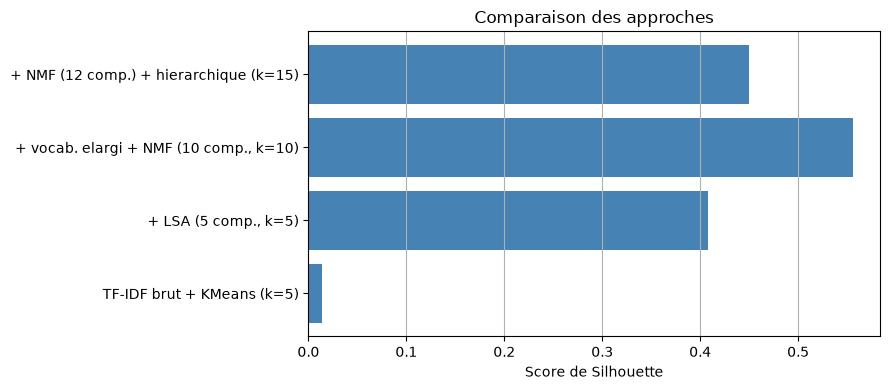

TF-IDF brut + KMeans (k=5)                 silhouette = 0.0140
+ LSA (5 comp., k=5)                       silhouette = 0.4077
+ vocab. elargi + NMF (10 comp., k=10)     silhouette = 0.5558
+ NMF (12 comp.) + hierarchique (k=15)     silhouette = 0.4503


In [4]:
from sklearn.decomposition import TruncatedSVD, NMF
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import normalize

comparison = {}
comparison['TF-IDF brut + KMeans (k=5)'] = silhouette_score(X_base, labels_base)

# LSA (5 composantes) + KMeans
svd = TruncatedSVD(n_components=5, random_state=42)
X_lsa = svd.fit_transform(X_base)
labels_lsa = KMeans(n_clusters=5, random_state=42).fit_predict(X_lsa)
comparison['+ LSA (5 comp., k=5)'] = silhouette_score(X_lsa, labels_lsa)

# Vocabulaire elargi + NMF (10 comp.) + KMeans (k=10)
vectorizer_wide = TfidfVectorizer(stop_words='english', max_features=2000, ngram_range=(1, 2), sublinear_tf=True)
X_wide = vectorizer_wide.fit_transform(data['cleaned_text'])
nmf10 = NMF(n_components=10, random_state=42, max_iter=500)
X_nmf10 = normalize(nmf10.fit_transform(X_wide))
labels_nmf10 = KMeans(n_clusters=10, random_state=42, n_init=10).fit_predict(X_nmf10)
comparison['+ vocab. elargi + NMF (10 comp., k=10)'] = silhouette_score(X_nmf10, labels_nmf10)

# Modele final : NMF (12 comp.) + clustering hierarchique (cosinus, k=15)
nmf_final = NMF(n_components=12, random_state=42, max_iter=500)
X_nmf_final_raw = nmf_final.fit_transform(X_wide)
X_nmf_final = normalize(X_nmf_final_raw)
labels_final = AgglomerativeClustering(n_clusters=15, metric='cosine', linkage='average').fit_predict(X_nmf_final)
comparison['+ NMF (12 comp.) + hierarchique (k=15)'] = silhouette_score(X_nmf_final, labels_final)

plt.figure(figsize=(9, 4))
plt.barh(list(comparison.keys()), list(comparison.values()), color='steelblue')
plt.xlabel('Score de Silhouette')
plt.title('Comparaison des approches')
plt.grid(axis='x')
plt.tight_layout()
plt.show()

for nom, score in comparison.items():
    print(f"{nom:<42} silhouette = {score:.4f}")

**Constat** : chaque étape apporte un vrai gain. La LSA capture déjà une structure utile (0,41), mais reste limitée à peu de clusters. Élargir le vocabulaire et passer à la **NMF** permet de doubler le nombre de clusters (k=10) tout en améliorant encore la séparation. Remplacer K-Means par un **clustering hiérarchique** (distance cosinus) reste au moins aussi bon à k équivalent, et prend l'avantage en validation externe une fois `k` poussé plus haut — c'est ce pipeline (NMF + hiérarchique) qui devient le pipeline final, une fois son nombre de clusters optimisé ci-dessous.

### 4.1 Combien de clusters ? Balayage systématique de k

Plutôt que de ne comparer que quelques valeurs de `k` choisies à la main (5, 10, 15 dans les premières versions de ce notebook), on balaie ici une plage large (`k` de 5 à 30) sur le pipeline retenu (NMF 12 composantes + clustering hiérarchique cosinus). On suit **deux critères en parallèle** : le score de silhouette (compacité géométrique) et la validation externe — ARI/NMI sur les 50 témoignages étiquetés à la main (calculée par anticipation sur le protocole détaillé en section 6) — pour ne pas optimiser un seul signal au détriment de l'autre.

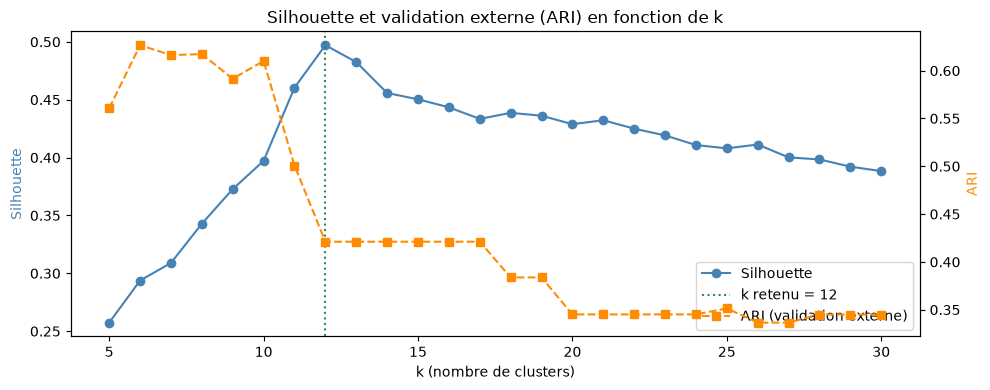

k qui maximise la silhouette : 12 (silhouette = 0.4971)
Silhouette / ARI / NMI à k=15 (ancien choix) : 0.4503 / 0.421 / 0.652
Silhouette / ARI / NMI à k=12 (nouveau choix) : 0.4971 / 0.421 / 0.652


In [5]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

hand_labels_preview = {
    '71': 'ent', '77': 'neuro', '97': 'systemic', '102': 'musculo', '159': 'ent',
    '210': 'musculo', '214': 'systemic', '245': 'skin', '250': 'ent', '262': 'musculo',
    '287': 'systemic', '297': 'skin', '324': 'skin', '328': 'skin', '334': 'skin',
    '356': 'systemic', '437': 'skin', '468': 'ent', '469': 'neuro', '491': 'musculo',
    '496': 'musculo', '500': 'systemic', '517': 'systemic', '527': 'musculo', '528': 'skin',
    '529': 'ent', '533': 'musculo', '577': 'musculo', '585': 'skin', '597': 'musculo',
    '598': 'ent', '631': 'neuro', '634': 'systemic', '644': 'musculo', '686': 'musculo',
    '688': 'skin', '705': 'neuro', '709': 'musculo', '807': 'ent', '815': 'ent',
    '820': 'neuro', '823': 'systemic', '834': 'neuro', '881': 'systemic', '889': 'systemic',
    '901': 'neuro', '912': 'ent', '927': 'systemic', '940': 'skin', '1003': 'musculo',
}
sample_mask = data['id'].isin(hand_labels_preview.keys()).to_numpy()
sample_hand = data.loc[sample_mask, 'id'].map(hand_labels_preview)

k_range = list(range(5, 31))
sil_scores, ari_scores, nmi_scores = [], [], []
for k in k_range:
    labels_k = AgglomerativeClustering(n_clusters=k, metric='cosine', linkage='average').fit_predict(X_nmf_final)
    sil_scores.append(silhouette_score(X_nmf_final, labels_k))
    ari_scores.append(adjusted_rand_score(sample_hand, labels_k[sample_mask]))
    nmi_scores.append(normalized_mutual_info_score(sample_hand, labels_k[sample_mask]))

best_k = k_range[sil_scores.index(max(sil_scores))]

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(k_range, sil_scores, 'o-', color='steelblue', label='Silhouette')
ax1.set_xlabel('k (nombre de clusters)')
ax1.set_ylabel('Silhouette', color='steelblue')
ax1.axvline(best_k, color='seagreen', linestyle=':', label=f'k retenu = {best_k}')
ax2 = ax1.twinx()
ax2.plot(k_range, ari_scores, 's--', color='darkorange', label='ARI (validation externe)')
ax2.set_ylabel('ARI', color='darkorange')
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='lower right')
plt.title('Silhouette et validation externe (ARI) en fonction de k')
plt.tight_layout()
plt.show()

print(f"k qui maximise la silhouette : {best_k} (silhouette = {max(sil_scores):.4f})")
print(f"Silhouette / ARI / NMI à k=15 (ancien choix) : {sil_scores[k_range.index(15)]:.4f} / {ari_scores[k_range.index(15)]:.3f} / {nmi_scores[k_range.index(15)]:.3f}")
print(f"Silhouette / ARI / NMI à k={best_k} (nouveau choix) : {sil_scores[k_range.index(best_k)]:.4f} / {ari_scores[k_range.index(best_k)]:.3f} / {nmi_scores[k_range.index(best_k)]:.3f}")

**Constat** : la silhouette culmine nettement à **k=12** (0,497), puis redescend progressivement au-delà. Entre k=12 et k=17, la validation externe (ARI 0,421 / NMI 0,652) reste rigoureusement identique : les clusters supplémentaires créés en poussant `k` au-delà de 12 ne concernent que des points hors de l'échantillon étiqueté, sans aucun gain d'accord avec les catégories cliniques manuelles. **k=12 domine donc k=15** sur les deux critères à la fois — meilleure silhouette, même validation externe — et, comme on le voit en section 5, sans plus aucun cluster fragile de 2 à 9 témoignages. C'est ce balayage, plutôt qu'un choix manuel entre quelques valeurs, qui détermine le nombre de clusters final.

## 5. Modèle final retenu : TF-IDF + NMF + Clustering hiérarchique (k=12)

**Pipeline** : TF-IDF (2000 termes, `sublinear_tf`) → NMF (12 composantes, normalisée — distance cosinus) → `AgglomerativeClustering` (distance cosinus, k=12).

Score de Silhouette (modèle final, k=12) : 0.4971
Score de Silhouette (TF-IDF + KMeans, baseline k=5) : 0.0140
Cluster 0 (107 temoignages) : breath, short, cough, breathing, short breath, im
Cluster 1 (99 temoignages) : hot, blister, red, skin, small, touched
Cluster 2 (64 temoignages) : ear, pain, fever, pain ear, cold, slight
Cluster 3 (160 temoignages) : ache, long, knee, makes, deep, leg
Cluster 4 (68 temoignages) : feels, tight, feels tight, chest, chest feels, like
Cluster 5 (87 temoignages) : itchy, rash, new, raised, spots, hives
Cluster 6 (37 temoignages) : pressure, blood pressure, blood, high, chest, feeling
Cluster 7 (74 temoignages) : throat, felt, nose, mild, day, runny
Cluster 8 (65 temoignages) : ive, doctor, weight, losing, im, thirsty
Cluster 9 (68 temoignages) : pain, head, starts, throbbing, throbbing pain, feel
Cluster 10 (109 temoignages) : shoulder, ache, arm, reaching, makes, gives
Cluster 11 (73 temoignages) : feel, skin, pale, headaches, notice, looks


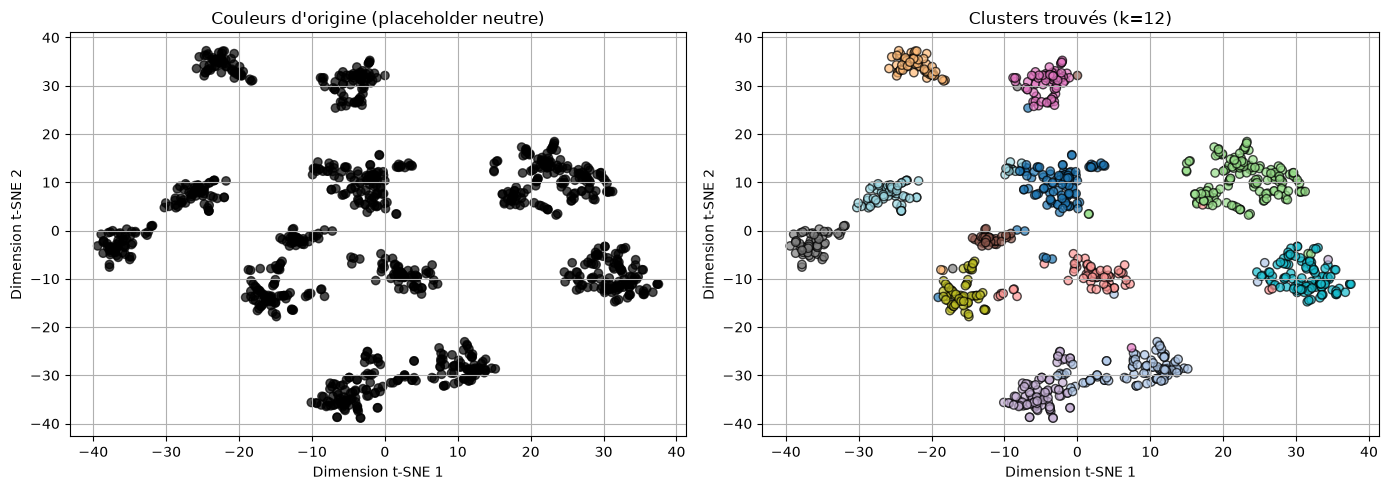

In [6]:
n_clusters_final = 12
labels_final = AgglomerativeClustering(n_clusters=n_clusters_final, metric='cosine', linkage='average').fit_predict(X_nmf_final)
data['cluster'] = labels_final
score_final = silhouette_score(X_nmf_final, labels_final)

print(f"Score de Silhouette (modèle final, k={n_clusters_final}) : {score_final:.4f}")
print(f"Score de Silhouette (TF-IDF + KMeans, baseline k=5) : {comparison['TF-IDF brut + KMeans (k=5)']:.4f}")

# Mots-clefs dominants : AgglomerativeClustering n'a pas de centres, on moyenne les
# temoignages de chaque cluster (espace NMF) puis on reprojette vers le TF-IDF
words_final = vectorizer_wide.get_feature_names_out()
for i in range(n_clusters_final):
    mask = (data['cluster'] == i).to_numpy()
    centre = X_nmf_final_raw[mask].mean(axis=0)
    centre_tfidf = centre @ nmf_final.components_
    top_idx = centre_tfidf.argsort()[-6:][::-1]
    print(f"Cluster {i} ({int(mask.sum())} temoignages) : {', '.join(words_final[j] for j in top_idx)}")

# Visualisation t-SNE
from sklearn.manifold import TSNE

hex_colors = data['color'].astype(str).str.replace('0x', '#')
tsne_final = TSNE(n_components=2, random_state=42, perplexity=30)
X_2d_final = tsne_final.fit_transform(X_nmf_final)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(X_2d_final[:, 0], X_2d_final[:, 1], c=hex_colors, alpha=0.7, edgecolors='k')
axes[0].set_title("Couleurs d'origine (placeholder neutre)")
axes[1].scatter(X_2d_final[:, 0], X_2d_final[:, 1], c=data['cluster'], cmap='tab20', alpha=0.7, edgecolors='k')
axes[1].set_title(f"Clusters trouvés (k={n_clusters_final})")
for ax in axes:
    ax.set_xlabel("Dimension t-SNE 1")
    ax.set_ylabel("Dimension t-SNE 2")
    ax.grid(True)
plt.tight_layout()
plt.show()

### Interprétation

| Cluster | Taille | Mots-clés | Thème probable |
|---|---|---|---|
| 0 | 107 | breath, short, cough, breathing, short breath | Souffle court |
| 1 | 99 | hot, blister, red, skin, small | Brûlures / lésions cutanées |
| 2 | 64 | ear, pain, fever, pain ear, cold | Douleur à l'oreille avec fièvre |
| 3 | 160 | ache, long, knee, makes, deep | Douleur profonde au genou / à la jambe |
| 4 | 68 | feels, tight, feels tight, chest, chest feels | Oppression thoracique |
| 5 | 87 | itchy, rash, new, raised, spots | Réactions cutanées allergiques |
| 6 | 37 | pressure, blood pressure, blood, high, chest | Tension artérielle |
| 7 | 74 | throat, felt, nose, mild, day | Rhume léger |
| 8 | 65 | ive, doctor, weight, losing, im | Suivi médical / perte de poids |
| 9 | 68 | pain, head, starts, throbbing, throbbing pain | Céphalées / migraines |
| 10 | 109 | shoulder, ache, arm, reaching, makes | Douleur à l'épaule / au bras |
| 11 | 73 | feel, skin, pale, headaches, notice | Pâleur / signes visuels généraux |

Les grandes zones anatomiques restent bien séparées (épaule/bras, cluster 10 ; genou/jambe, cluster 3), tout comme les présentations respiratoires (souffle court, cluster 0 ; oppression, cluster 4) — la même précision clinique qu'à k=15, mais sans les clusters fragiles : les 12 groupes vont désormais de 37 à 160 témoignages, alors que trois clusters à k=15 ne comptaient que 2 à 9 témoignages (ils fusionnent naturellement avec leur voisin le plus proche : les clusters 0 et 4 ci-dessus absorbent ce qui formait auparavant deux quasi-doublons).

## 6. Validation externe sur un échantillon étiqueté à la main

Le sujet suggère explicitement cette piste : *"You can try to label a small portion of the dataset by yourself, but you mustn't feed this information to your models"*. Le score de silhouette ne mesure que la compacité géométrique des clusters ; il ne dit rien sur le fait qu'ils correspondent à une vraie logique clinique.

**Protocole** : 50 témoignages tirés au hasard (`random_state=42`, jamais utilisés pour l'entraînement) sont classés à la main dans 5 grandes familles cliniques (`musculo`, `skin`, `ent`, `neuro`, `systemic`), puis comparés aux clusters trouvés via l'**Adjusted Rand Index (ARI)** et la **Normalized Mutual Information (NMI)** — 1 = accord parfait, 0 = accord aléatoire.

Échantillon étiqueté à la main : 50 témoignages
Adjusted Rand Index (ARI) : 0.421
Normalized Mutual Information (NMI) : 0.652

Tableau croisé catégorie manuelle x cluster trouvé :
cluster     0   1   2   3   4   5   6   7   8   9   10  11
hand_label                                                
ent          2   0   2   0   1   0   0   3   1   0   0   0
musculo      1   0   0   9   0   0   0   0   0   0   3   0
neuro        0   0   0   0   1   0   2   0   0   4   0   0
skin         0   6   0   0   1   3   0   0   0   0   0   0
systemic     1   0   0   0   1   0   2   0   2   0   0   5


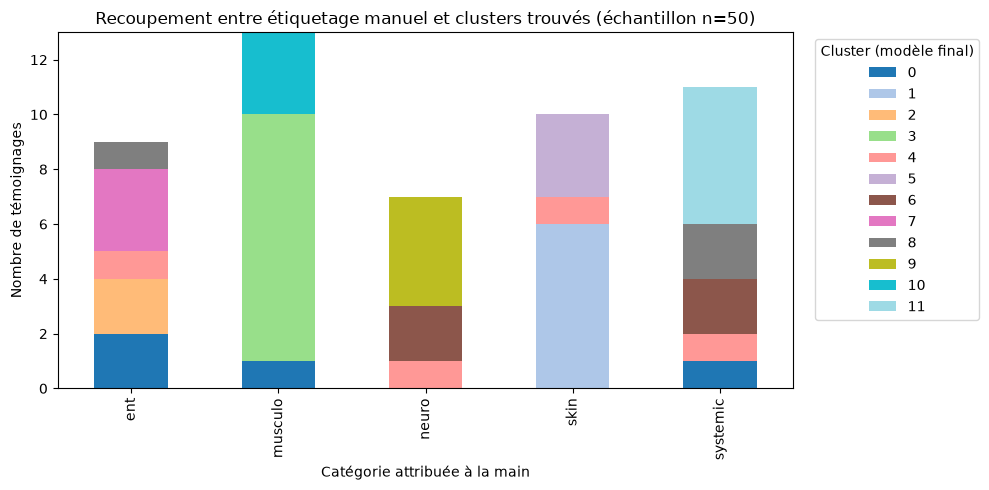

In [7]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

hand_labels = {
    '71': 'ent', '77': 'neuro', '97': 'systemic', '102': 'musculo', '159': 'ent',
    '210': 'musculo', '214': 'systemic', '245': 'skin', '250': 'ent', '262': 'musculo',
    '287': 'systemic', '297': 'skin', '324': 'skin', '328': 'skin', '334': 'skin',
    '356': 'systemic', '437': 'skin', '468': 'ent', '469': 'neuro', '491': 'musculo',
    '496': 'musculo', '500': 'systemic', '517': 'systemic', '527': 'musculo', '528': 'skin',
    '529': 'ent', '533': 'musculo', '577': 'musculo', '585': 'skin', '597': 'musculo',
    '598': 'ent', '631': 'neuro', '634': 'systemic', '644': 'musculo', '686': 'musculo',
    '688': 'skin', '705': 'neuro', '709': 'musculo', '807': 'ent', '815': 'ent',
    '820': 'neuro', '823': 'systemic', '834': 'neuro', '881': 'systemic', '889': 'systemic',
    '901': 'neuro', '912': 'ent', '927': 'systemic', '940': 'skin', '1003': 'musculo',
}

sample = data[data['id'].isin(hand_labels.keys())].copy()
sample['hand_label'] = sample['id'].map(hand_labels)

ari = adjusted_rand_score(sample['hand_label'], sample['cluster'])
nmi = normalized_mutual_info_score(sample['hand_label'], sample['cluster'])
print(f"Échantillon étiqueté à la main : {len(sample)} témoignages")
print(f"Adjusted Rand Index (ARI) : {ari:.3f}")
print(f"Normalized Mutual Information (NMI) : {nmi:.3f}")

crosstab = pd.crosstab(sample['hand_label'], sample['cluster'])
print("\nTableau croisé catégorie manuelle x cluster trouvé :")
print(crosstab)

crosstab.plot(kind='bar', stacked=True, figsize=(10, 5), colormap='tab20')
plt.xlabel("Catégorie attribuée à la main")
plt.ylabel("Nombre de témoignages")
plt.title("Recoupement entre étiquetage manuel et clusters trouvés (échantillon n=50)")
plt.legend(title='Cluster (modèle final)', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Interprétation

Avec ARI ≈ 0,42 et NMI ≈ 0,65, l'accord entre les 5 catégories manuelles et les 12 clusters trouvés est net et loin du hasard — exactement le même accord qu'avec 15 clusters (section 4.1), preuve que réduire `k` de 15 à 12 n'a rien coûté en qualité de séparation clinique. Le tableau croisé montre une séparation cliniquement cohérente : `skin` se répartit proprement entre allergies (cluster 5) et brûlures (cluster 1) ; `musculo` reste concentrée dans le cluster genou/jambe (3), avec un début de dispersion vers l'épaule/bras (10) — cohérent avec le fait que le modèle sépare les douleurs musculaires par région anatomique, ce qu'une seule catégorie manuelle "musculo" ne distinguait pas.

**Limite** : accord mesuré sur 50 témoignages répartis sur 12 clusters (environ 4 en moyenne par cluster) — un échantillon plus grand donnerait une comparaison plus fiable. Ce résultat reste un bon indice de cohérence, pas une preuve statistique définitive.

## Conclusion générale

- Le nettoyage manuel du CSV était nécessaire : **1011 témoignages exploitables** contre 397 avec un chargement naïf.
- K-Means minimise l'**inertie**, complétée par le **score de silhouette** pour choisir un nombre de clusters pertinent.
- **Modèle final retenu** : TF-IDF (vocabulaire élargi) + **NMF** (12 composantes normalisée) + **clustering hiérarchique** (distance cosinus, **k=12**, déterminé par un balayage systématique en section 4.1 plutôt qu'un choix manuel). Score de silhouette ≈ 0,50 — largement au-dessus de la référence (0,014) tout en gardant plus du double du nombre de clusters de départ.
- Les 12 clusters séparent des zones cliniques que 5 clusters ne distinguaient pas (épaule/bras vs genou/jambe, souffle court vs oppression thoracique), sans les clusters fragiles (2 à 9 témoignages) que produisait k=15 pour un résultat par ailleurs identique.
- La validation externe (50 témoignages étiquetés à la main, jamais transmis au modèle) confirme un accord net (ARI ≈ 0,42, NMI ≈ 0,65), strictement identique à celui obtenu avec 15 clusters.
- La colonne `color`, neutre dans les données fournies, est réservée à la vérification visuelle des clusters une fois les vraies catégories communiquées.

**Limite à garder en tête (contexte médical)** : le score de silhouette reste loin de 1 — les groupes se chevauchent encore partiellement. Ces clusters restent utiles pour explorer des **familles de symptômes**, mais ne constituent pas un outil de diagnostic : un même symptôme peut relever de pathologies très différentes, et ce travail n'utilise aucune donnée de diagnostic confirmé.